# Week 11 In-Class Demo 1
## Cleaning Large Health Data and Building a Reproducible Pipeline

### Business question
A regional health-services organization wants to identify patients who may be readmitted within 30 days. Earlier identification could help the organization plan follow-up calls, medication reviews, discharge support, or family-care coordination.

This notebook uses a **synthetic dataset with 120,500 rows**. It contains intentionally dirty values so that we can practise realistic data cleaning before building a simple classification workflow.

> **Important:** The data are synthetic and are for teaching only. They do not represent real patients and must not be used for clinical decisions.

## What you will do
By the end of this demonstration, you should be able to:

1. inspect a large CSV without trying to read every row;
2. identify missing values, invalid numbers, inconsistent categories, and duplicate records;
3. separate business-rule cleaning from machine-learning preprocessing;
4. prevent data leakage by splitting before fitting imputers, scalers, encoders, or a model;
5. use `ColumnTransformer` for numerical and categorical columns;
6. use `Pipeline` to connect preprocessing and logistic regression;
7. explain accuracy, precision, recall, and a confusion matrix in business language;
8. apply the fitted workflow to new records with the same schema.

## How this builds on Week 10
In Week 10, you learned the basic idea of a machine-learning model: predictors go into a model, the model learns patterns, and the model produces a prediction.

This week answers a practical question that businesses face before any model can work:

> **How do we turn messy operational data into a consistent, repeatable input for a model?**

The main learning goal is not to memorize every line of code. Focus on the business logic:

1. identify what is wrong with the data;
2. decide which corrections are defensible;
3. protect the test data from influencing training;
4. make sure every future record receives the same treatment;
5. interpret the result in terms of organizational decisions.

Logistic regression is included as a familiar baseline model. The new material is the **cleaning and pipeline process around the model**.

## Lecture 19 resources
Use this notebook as the in-class guide and as a review resource.

- [Lecture 19 recording](https://nait.video.yuja.com/V/Video?v=1347379&node=7565674&a=1931007438)
- [Lecture 19 reference notebook](https://nbviewer.org/github/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/lectures/Lecture19_pipeline_impute_part_1.ipynb)
- [Student workbook: Lectures 19–20](https://github.com/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/workbooks/Lecture19_20_workbook.ipynb)
- [Student workbook solution](https://colab.research.google.com/drive/18WBBlkbv0hG263aULFziahDP4pIQDkuG?usp=sharing)
- [O’Reilly book: *Machine Learning with Python for Everyone*](https://learning.oreilly.com/library/view/machine-learning-with/9780134845708/)
  - **Chapter 10: Manual Feature Engineering: Manipulating Data for Fun and Profit**
- [Machine Learning Assignment 2](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=182241&type=dropbox&rcode=EE964922-8905-4C5B-ACC8-340F77B2A0B1-551201)
- [Term Project](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=182241&type=dropbox&rcode=EE964922-8905-4C5B-ACC8-340F77B2A0B1-551222)

## Dataset dictionary

| Column | Business meaning | General type |
|---|---|---|
| `patient_id` | Synthetic record identifier | Identifier, exclude from modeling |
| `age` | Age in years | Numerical |
| `gender` | Self-reported category | Categorical |
| `region` | Alberta service region | Categorical |
| `bmi` | Body mass index | Numerical |
| `systolic_bp` | Systolic blood pressure | Numerical |
| `cholesterol_mmol_l` | Cholesterol measurement | Numerical |
| `hba1c_pct` | HbA1c percentage | Numerical |
| `smoker_status` | Never, former, or current smoking status | Categorical |
| `activity_level` | Low, moderate, or high | Categorical |
| `chronic_conditions` | Count of recorded chronic conditions | Numerical count |
| `prior_admissions` | Previous hospital admissions | Numerical count |
| `avg_visit_cost` | Average visit cost in dollars | Numerical |
| `insurance_type` | Employer, government, private, or uninsured | Categorical |
| `appointment_wait_days` | Days waited for the appointment | Numerical count |
| `missed_appointments` | Number of missed appointments | Numerical count |
| `readmitted_30d` | 1 = readmitted within 30 days; 0 = not readmitted | Target |

The dataset intentionally includes blank cells, `NA`, `N/A`, `unknown`, impossible numeric values, category aliases, extra spaces, inconsistent capitalization, and 500 duplicate rows.

> **BBA note:** You do not need medical expertise for this exercise. Treat the health measurements as business-data fields that require type checks, missing-value handling, validation rules, and clear documentation. The synthetic health context simply gives us a realistic operational dataset.

## Before the setup code: what are these libraries for?
The first code cell imports tools that play different roles.

| Tool | Plain-language role |
|---|---|
| `numpy` | Handles numerical operations and missing values such as `np.nan` |
| `pandas` | Loads, inspects, cleans, and organizes table-shaped data |
| `matplotlib` | Displays the confusion matrix |
| `train_test_split` | Creates separate training and test samples |
| `SimpleImputer` | Learns how to fill missing values |
| `StandardScaler` | Places numerical variables on comparable scales |
| `OneHotEncoder` | Converts categories into model-ready indicator columns |
| `ColumnTransformer` | Sends different columns through different preparation steps |
| `Pipeline` | Keeps preprocessing and the model in one repeatable sequence |
| `LogisticRegression` | Produces probabilities and predictions for a two-class outcome |

You do not need to memorize the import statements. You should understand the job performed by each component.

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
print("Setup complete.")

Setup complete.


### How to discuss the baseline result
The baseline model produces strong overall accuracy but much lower recall for readmission than for non-readmission. This is a valuable teaching result rather than a failure of the notebook.

For a BBA audience, the key question is:

> **Would an organization be satisfied with a model that classifies most records correctly but identifies only a small share of actual readmissions?**

Possible business responses include changing the decision threshold, collecting better predictors, reconsidering feature definitions, comparing other models, or changing how the prediction is used. Those are later modeling decisions. The immediate lesson is that one metric cannot describe the full business usefulness of a model.

## 1. Load one large health dataset
The CSV contains more than 100,000 rows. We will use `low_memory=False` because several dirty numeric columns contain text entries such as `unknown` and `high`.

A large row count does not automatically mean high-quality data. Before modeling, we need to understand the dataset's structure and business meaning.

### Why load from a separate CSV?
Businesses normally store data outside a notebook in files, databases, or cloud systems. Keeping the CSV separate mirrors a realistic workflow and makes it possible to reuse the same data in another notebook.

`DATA_PATH` stores the filename in one place. If the file location changes, we update one line instead of searching through the entire notebook.

`pd.read_csv(..., low_memory=False)` asks pandas to inspect the file more consistently before assigning column types. That is useful here because some columns contain both numbers and intentionally dirty text.

In [33]:
DATA_PATH = "healthcare_readmission.csv"

df_raw = pd.read_csv(DATA_PATH, low_memory=False)
print("Rows and columns:", df_raw.shape)
display(df_raw.head())

Rows and columns: (120500, 17)


,patient_id,age,gender,region,bmi,systolic_bp,cholesterol_mmol_l,hba1c_pct,smoker_status,activity_level,chronic_conditions,prior_admissions,avg_visit_cost,insurance_type,appointment_wait_days,missed_appointments,readmitted_30d
0,P0000001,57,Male,Calgary,30.5,132.0,3.44,7.4,Former,Moderate,2,0,687.67,Employer,19,0,0
1,P0000002,34,Male,Southern Alberta,21.9,164.0,3.69,5.1,Never,Moderate,2,0,522.70,Employer,4,1,0
2,P0000003,65,Male,Calgary,29.5,141.0,3.98,7.1,Former,Moderate,0,0,239.01,Employer,7,0,0
3,P0000004,68,Male,Calgary,29.3,146.0,6.60,5.2,Never,Low,2,0,478.34,Employer,4,0,0
4,P0000005,19,Male,Edmonton,36.4,146.0,4.52,5.8,Never,Moderate,1,0,494.69,Government,6,0,0


## Check-in 1: What should we inspect first?
Before running more code, identify at least four checks you would complete before modeling.

<details>
<summary><strong>Reveal suggested response</strong></summary>

Useful first checks include:

- row and column counts;
- column names and data types;
- missing or placeholder values;
- duplicate records;
- impossible values such as negative age or BMI;
- inconsistent category labels such as `Female`, `female`, and `F`;
- target balance;
- whether an ID or post-outcome field should be excluded.

The goal is not to clean everything automatically. Each change should have a business or data-quality reason.

</details>

## 2. Profile the dirty data
For a dataset this large, summaries are more useful than scrolling. We examine data types, missingness, duplicates, target balance, and selected category values.

### What the profile table tells a business analyst
The profile is a quick data-quality inventory.

- **`dtype`** shows how pandas currently understands a field. A numerical business measure stored as `object` is a warning that text may be mixed into the column.
- **`missing_cells`** shows how much information is unavailable.
- **`unique_values`** can reveal identifiers, unexpected categories, or unusually varied measurements.
- **Duplicate count** helps determine whether the same record may be represented more than once.
- **Target distribution** shows the proportion of readmitted and non-readmitted records.

The profile does not decide the cleaning strategy. It tells us where investigation is needed.

In [37]:
profile = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_cells": df_raw.isna().sum(),
    "unique_values": df_raw.nunique(dropna=True)
})
display(profile)

print("Exact duplicate rows:", df_raw.duplicated().sum())
print()
print("Target distribution:")
print(df_raw["readmitted_30d"].value_counts(normalize=True).sort_index().round(3))

,dtype,missing_cells,unique_values
patient_id,object,0,120000
age,object,2003,78
gender,object,2749,12
region,object,1430,15
bmi,object,4294,355
systolic_bp,float64,3596,119
cholesterol_mmol_l,object,2720,626
hba1c_pct,object,4797,61
smoker_status,object,2063,12
activity_level,object,3523,9


Exact duplicate rows: 500

Target distribution:
readmitted_30d
0    0.856
1    0.144
Name: proportion, dtype: float64


### Why inspect category frequencies?
A category column can look acceptable in the first five rows while containing many hidden versions of the same idea.

For example, `Female`, `female`, `F`, and ` Female ` may all represent one business category. If they are left unchanged, one-hot encoding will treat them as different groups. That makes reports harder to interpret and adds unnecessary model columns.

`value_counts(dropna=False)` helps us see both frequent labels and missing values. We inspect only the first 15 counts because a concise summary is easier to discuss than a full printout.

In [39]:
for col in ["gender", "region", "smoker_status", "activity_level", "insurance_type"]:
    print()
    print(f"{col}: top raw values")
    print(df_raw[col].value_counts(dropna=False).head(15))


gender: top raw values
gender
Female        56624
Male          53295
NaN            2749
Non-binary     2289
Unknown        1323
 Female         579
M               546
female          537
NB              536
F               515
male            505
nonbinary       504
 Male           498
Name: count, dtype: int64

region: top raw values
region
Edmonton            38414
Calgary             33802
Central Alberta     15663
Northern Alberta    13630
Southern Alberta    11085
unknown              1452
NaN                  1430
edmonton              599
North                 572
EDM                   571
central alberta       566
 Edmonton             560
calgary               559
YYC                   533
south                 533
Name: count, dtype: int64

smoker_status: top raw values
smoker_status
Never       65493
Former      28142
Current     19147
NaN          2063
Unknown      2042
never         514
Current       472
current       462
former        449
N             439
Never      

## Check-in 2: Why are some numeric columns stored as text?
`age`, `bmi`, and some other measurements may appear as `object` rather than numerical data types.

<details>
<summary><strong>Reveal explanation</strong></summary>

A single text value such as `unknown`, `two`, or `high` can cause a column to be read as text. Before calculating averages or passing the column to a model, we need to replace known missing tokens and convert the remaining valid values to numbers.

Using `pd.to_numeric(..., errors="coerce")` converts valid numeric text and changes unconvertible text to `NaN`, which can then be handled deliberately.

</details>

## 3. Create a cleaning copy
We preserve `df_raw` as the original import and create `df` as the working copy. This makes the cleaning process auditable and lets us compare before and after results.

### Why keep `df_raw` unchanged?
An original copy provides an audit trail. If a cleaning rule produces an unexpected result, we can compare the cleaned value with the imported value instead of reloading the file or guessing what changed.

The working pattern is:

- `df_raw`: original imported data, left unchanged;
- `df`: working copy used for cleaning and modeling.

We first standardize known missing tokens. The strings `NA`, `N/A`, and `unknown` all mean that a usable value is unavailable, so we convert them to one consistent marker: `np.nan`.

We also remove **exact** duplicate rows. This is a cautious rule. Records that merely look similar are not automatically duplicates because two different patients can share the same age, region, or measurements.

In [43]:
df = df_raw.copy()

# Standardize common missing-value tokens.
missing_tokens = ["", "NA", "N/A", "unknown", "Unknown"]
df = df.replace(missing_tokens, np.nan)

# Remove exact duplicate rows.
rows_before = len(df)
df = df.drop_duplicates().copy()
print("Duplicate rows removed:", rows_before - len(df))

Duplicate rows removed: 500


## 4. Convert and validate numerical columns
There are two separate actions:

1. **Type conversion:** turn valid numeric text into numbers and invalid text into missing values.
2. **Business-rule validation:** treat impossible or implausible values as missing.

In a real organization, the ranges below should be reviewed with data stewards and clinical subject-matter experts. Here they are teaching rules for a synthetic dataset.

### Step-by-step rationale for numerical cleaning
This code follows a two-stage process.

#### Stage 1: Convert types
`pd.to_numeric(errors="coerce")` keeps valid numbers and converts unrecognized text to missing values. For example:

- `"52"` becomes `52`;
- `"28.4"` becomes `28.4`;
- `"two"` becomes `NaN`;
- `"high"` becomes `NaN`.

#### Stage 2: Apply teaching ranges
A number can have the correct data type and still be implausible. Age `140` and BMI `350` are numerical, but they do not fit the documented teaching ranges.

The dictionary `valid_ranges` makes the rules visible and reviewable. We count the affected values before turning them into missing values. In a real health organization, these thresholds would require approval from data stewards and clinical subject-matter experts.

We do **not** impute yet. At this stage, we identify invalid information. The pipeline will later learn replacement values from training data only.

In [46]:
numeric_columns = [
    "age", "bmi", "systolic_bp", "cholesterol_mmol_l", "hba1c_pct",
    "chronic_conditions", "prior_admissions", "avg_visit_cost",
    "appointment_wait_days", "missed_appointments"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

valid_ranges = {
    "age": (18, 100),
    "bmi": (12, 70),
    "systolic_bp": (70, 250),
    "cholesterol_mmol_l": (1, 15),
    "hba1c_pct": (3, 20),
    "chronic_conditions": (0, 15),
    "prior_admissions": (0, 20),
    "avg_visit_cost": (0, 20000),
    "appointment_wait_days": (0, 365),
    "missed_appointments": (0, 30)
}

invalid_counts = {}
for col, (low, high) in valid_ranges.items():
    invalid = df[col].notna() & ~df[col].between(low, high)
    invalid_counts[col] = int(invalid.sum())
    df.loc[invalid, col] = np.nan

pd.Series(invalid_counts, name="values_changed_to_missing").to_frame()

,values_changed_to_missing
age,541
bmi,900
systolic_bp,700
cholesterol_mmol_l,0
hba1c_pct,316
chronic_conditions,0
prior_admissions,0
avg_visit_cost,296
appointment_wait_days,0
missed_appointments,0


## Check-in 3: Why change impossible values to missing instead of zero?

<details>
<summary><strong>Reveal explanation</strong></summary>

Zero is a real number. Replacing an impossible BMI or a text entry with zero would tell the model that the patient truly had a BMI of zero. That would add false information.

Changing invalid values to `NaN` clearly marks them as unavailable. A later imputer can then fill those values using a rule learned from training data only.

</details>

## 5. Standardize categorical values
Business datasets often contain the same category in several forms because of manual entry, multiple systems, or historical coding practices. We first trim spaces and standardize capitalization, then map known aliases to one approved label.

### Step-by-step rationale for categorical cleaning
Categorical cleaning has three parts:

1. **Convert to a consistent string format.**
2. **Trim extra spaces and standardize case.**
3. **Map known aliases to approved labels.**

For example:

- `" Female "`, `"female"`, and `"F"` become `"Female"`;
- `"EDM"` and `"edmonton"` become `"Edmonton"`;
- `"Govt"` and `"government "` become `"Government"`.

The mapping dictionaries are intentionally explicit. That makes the business rules easy to review. A short mapping may look less clever than a complicated automated function, but it is often easier to explain, audit, and maintain.

In [50]:
categorical_columns = [
    "gender", "region", "smoker_status", "activity_level", "insurance_type"
]

for col in categorical_columns:
    df[col] = df[col].astype("string").str.strip().str.lower()

category_maps = {
    "gender": {
        "f": "Female", "female": "Female",
        "m": "Male", "male": "Male",
        "nb": "Non-binary", "nonbinary": "Non-binary", "non-binary": "Non-binary"
    },
    "region": {
        "edmonton": "Edmonton", "edm": "Edmonton",
        "calgary": "Calgary", "yyc": "Calgary",
        "central alberta": "Central Alberta",
        "northern alberta": "Northern Alberta", "north": "Northern Alberta",
        "southern alberta": "Southern Alberta", "south": "Southern Alberta"
    },
    "smoker_status": {
        "never": "Never", "n": "Never",
        "former": "Former",
        "current": "Current", "y": "Current"
    },
    "activity_level": {
        "low": "Low", "moderate": "Moderate", "high": "High"
    },
    "insurance_type": {
        "employer": "Employer",
        "govt": "Government", "government": "Government",
        "private": "Private",
        "un-insured": "Uninsured", "uninsured": "Uninsured"
    }
}

for col, mapping in category_maps.items():
    df[col] = df[col].map(mapping).astype(object)
    df[col] = df[col].where(pd.notna(df[col]), np.nan)

for col in categorical_columns:
    print(f"{col}: {sorted(df[col].dropna().unique().tolist())}")

gender: ['Female', 'Male', 'Non-binary']
region: ['Calgary', 'Central Alberta', 'Edmonton', 'Northern Alberta', 'Southern Alberta']
smoker_status: ['Current', 'Former', 'Never']
activity_level: ['High', 'Low', 'Moderate']
insurance_type: ['Employer', 'Government', 'Private', 'Uninsured']


## Check-in 4: What happens to an unmapped category?

<details>
<summary><strong>Reveal explanation</strong></summary>

After `.map(mapping)`, a value not listed in the approved mapping becomes missing. That is safer than silently inventing a category, but it also means the mapping must be reviewed.

A real organization would maintain approved code lists, log unexpected values, and investigate whether they represent a valid new category or a data-entry problem.

</details>

## 6. Review the cleaned structure
At this point we have applied deterministic cleaning rules that do not depend on the target or on averages calculated from the full dataset. Missing values remain, and that is intentional. Imputation will be fitted later using training data only.

### Two kinds of preparation are happening in this notebook
It helps to separate them:

- **Rule-based cleaning before the split:** remove exact duplicates, interpret documented missing tokens, convert types, standardize known aliases, and flag clearly invalid values. These rules do not learn averages, medians, category frequencies, or model patterns from the dataset.
- **Learned preprocessing after the split:** imputation, scaling, and one-hot encoding are fitted using training data inside the pipeline.

This distinction explains why some cleaning occurs before the split while data-dependent preprocessing occurs after it.

### Why review the dataset again?
Cleaning should always be followed by a quality check. We want to confirm that:

- numerical fields now have numerical data types;
- approved category labels are consistent;
- exact duplicates were removed;
- missing values remain visible rather than being hidden;
- the target was not accidentally changed.

This is a control step. In business analytics, a transformation is not complete merely because the code ran without an error.

In [54]:
cleaning_summary = pd.DataFrame({
    "dtype_after_cleaning": df.dtypes.astype(str),
    "missing_after_cleaning": df.isna().sum(),
    "unique_after_cleaning": df.nunique(dropna=True)
})
display(cleaning_summary)
print("Cleaned rows and columns:", df.shape)

,dtype_after_cleaning,missing_after_cleaning,unique_after_cleaning
patient_id,object,0,120000
age,float64,3681,73
gender,object,4058,3
region,object,2869,5
bmi,float64,7455,350
systolic_bp,float64,4281,115
cholesterol_mmol_l,float64,5400,625
hba1c_pct,float64,5276,58
smoker_status,object,4087,3
activity_level,object,3504,3


Cleaned rows and columns: (120000, 17)


## 7. Optional business feature engineering
We can create simple, understandable features using domain and operational knowledge.

- `high_service_use`: whether prior admissions or missed appointments are relatively high.
- `risk_measure_count`: count of selected measurements above teaching thresholds.

These are hypotheses, not guaranteed improvements. They are designed to be understandable to business stakeholders.

### How to read the feature-engineering code
A feature is a new variable created from available information.

`high_service_use` combines two operational indicators into a simple Yes/No field. It may help a manager understand whether a patient has had relatively high use of services.

`risk_measure_count` counts how many of three **illustrative teaching thresholds** are met:

- BMI at least 30;
- systolic blood pressure at least 140;
- HbA1c at least 6.5.

The feature is deliberately simple and interpretable. These thresholds are included only to demonstrate feature engineering with the synthetic data. The feature does not diagnose a patient, define clinical risk, or prove causation. It summarizes selected data in a form that may be useful for modeling or discussion.

The `.fillna(False)` part prevents a missing measurement from being counted as exceeding a threshold. This is a practical teaching choice, but a real project should document and review that assumption.

In [57]:
df["high_service_use"] = np.where(
    (df["prior_admissions"] >= 2) | (df["missed_appointments"] >= 3),
    "Yes",
    "No"
)

df["risk_measure_count"] = (
    (df["bmi"] >= 30).fillna(False).astype(int)
    + (df["systolic_bp"] >= 140).fillna(False).astype(int)
    + (df["hba1c_pct"] >= 6.5).fillna(False).astype(int)
)

display(df[["bmi", "systolic_bp", "hba1c_pct", "high_service_use", "risk_measure_count"]].head())

,bmi,systolic_bp,hba1c_pct,high_service_use,risk_measure_count
0,30.5,132.0,7.4,No,2
1,21.9,164.0,5.1,No,1
2,29.5,141.0,7.1,No,2
3,29.3,146.0,5.2,No,1
4,36.4,146.0,5.8,No,2


## Check-in 5: Is an understandable feature automatically useful?

<details>
<summary><strong>Reveal suggested response</strong></summary>

No. An understandable feature can still be redundant, noisy, unfair, unavailable at prediction time, or unrelated to the outcome.

We should keep a feature only when:

- it has a clear business meaning;
- its source data are available when the prediction is made;
- it does not directly reveal the target;
- its effect is evaluated using a consistent validation approach;
- its use is appropriate for the decision context.

</details>

## 8. Separate predictors, target, and protected test data
`patient_id` identifies a record and should not be used as a predictor. We also separate the target before creating the train-test split.

The test set represents unseen data. Imputation, scaling, encoding, and model fitting must learn from the training data only.

### Why separate `X`, `y`, training data, and test data?
Scikit-learn uses a common notation:

- **`X`** contains the predictor columns used to make a prediction;
- **`y`** contains the outcome we want to predict.

We remove `patient_id` because an identifier labels a record but does not describe a business condition that should drive readmission risk.

The split creates two roles:

- **Training data:** used to learn missing-value replacements, scales, category columns, and model coefficients.
- **Test data:** held back until the workflow is fitted, then used to estimate performance on unseen records.

`stratify=y` keeps approximately the same readmission percentage in both samples. `random_state=42` makes the split reproducible for classroom discussion.

In [61]:
X = df.drop(columns=["patient_id", "readmitted_30d"])
y = df["readmitted_30d"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training readmission rate:", round(y_train.mean(), 3))
print("Test readmission rate:", round(y_test.mean(), 3))

Training rows: 96000
Test rows: 24000
Training readmission rate: 0.144
Test readmission rate: 0.144


## Check-in 6: Why not fill missing values before the split?

<details>
<summary><strong>Reveal explanation</strong></summary>

If a median, average, or most-common category is calculated from the entire dataset, the test records influence the training process. This is data leakage.

Putting imputation inside the pipeline ensures that replacement values are learned from `X_train` and then reused for `X_test` and future records.

</details>

## 9. Build numerical and categorical preprocessing branches
The two data types need different treatments.

### Numerical branch
1. Replace missing values with the training median.
2. Standardize the numerical scale.

### Categorical branch
1. Replace missing categories with the most common training category.
2. Convert categories into one-hot indicator columns.

`ColumnTransformer` applies the appropriate branch to each column group.

### Reading the preprocessing design
We first list the columns assigned to each branch. This is important because each column should receive preparation that matches its meaning.

#### Numerical branch
`SimpleImputer(strategy="median")` learns one median per numerical column from the training data. The median is a useful baseline when a variable may contain unusually large values.

`StandardScaler()` then subtracts the training mean and divides by the training standard deviation. After scaling, a value is interpreted relative to the typical spread of that variable rather than in its original units.

For **logistic regression**, scaling is not required merely because one variable has larger numbers than another. Logistic regression can adjust its coefficients for different units. We scale here because it creates a consistent numerical preprocessing workflow and is especially useful when regularization or scale-sensitive models are introduced later.

#### Categorical branch
`SimpleImputer(strategy="most_frequent")` learns the most common training category for each categorical field.

`OneHotEncoder()` creates indicator columns. For example, one `region` column becomes several 0/1 columns such as `region_Edmonton` and `region_Calgary`.

#### Combining the branches
`ColumnTransformer` sends numerical columns through the numerical steps and categorical columns through the categorical steps, then joins the transformed results into one model-ready table.

In [65]:
numeric_features = [
    "age", "bmi", "systolic_bp", "cholesterol_mmol_l", "hba1c_pct",
    "chronic_conditions", "prior_admissions", "avg_visit_cost",
    "appointment_wait_days", "missed_appointments", "risk_measure_count"
]

categorical_features = [
    "gender", "region", "smoker_status", "activity_level",
    "insurance_type", "high_service_use"
]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'bmi', 'systolic_bp',
                                  'cholesterol_mmol_l', 'hba1c_pct',
                                  'chronic_conditions', 'prior_admissions',
                                  'avg_visit_cost', 'appointment_wait_days',
                                  'missed_appointments',
                                  'risk_measure_count']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['gender', 'region', 'smoker_status',
                                  'activity_level', 'insurance_type',
                                  'high_service_use'])])

## Check-in 7: Why use `handle_unknown="ignore"`?

<details>
<summary><strong>Reveal explanation</strong></summary>

A future record may contain a category not present in the training data. Without `handle_unknown="ignore"`, the encoder can raise an error.

Ignoring an unknown category allows the workflow to continue, but it does not mean the model understands that new category. Frequent unknown values should be monitored because they may indicate changing data or an incomplete approved mapping.

</details>

## 10. Connect preprocessing and one classifier
A `Pipeline` creates one ordered workflow:

`cleaned row → imputation → scaling/encoding → logistic regression → probability → prediction`

Logistic regression is used because it is a common, explainable baseline for a binary business problem. This demonstration focuses on constructing one correct workflow.

### What happens when the pipeline is fitted?
The pipeline is an ordered business process written as code.

When `model.fit(X_train, y_train)` runs, scikit-learn:

1. learns numerical medians from `X_train`;
2. fills missing numerical values;
3. learns numerical means and standard deviations;
4. scales numerical values;
5. learns the most frequent categories;
6. fills missing categorical values;
7. learns which one-hot columns are required;
8. transforms the training records;
9. fits logistic regression using the transformed records.

When `model.predict(X_test)` runs, the pipeline reuses those learned training rules. It does not recalculate them from the test set.

This consistency is the main reason pipelines are valuable. The organization does not need separate manual instructions for training data, test data, and future records.

In [69]:
model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, pred, digits=3, zero_division=0))

Test accuracy: 0.865
              precision    recall  f1-score   support

           0      0.873     0.986     0.926     20534
           1      0.647     0.150     0.244      3466

    accuracy                          0.865     24000
   macro avg      0.760     0.568     0.585     24000
weighted avg      0.840     0.865     0.828     24000



## 11. Interpret results in business language

- **Accuracy:** percentage of all test records classified correctly.
- **Readmission recall:** among patients who were readmitted, percentage the model identified.
- **Readmission precision:** among patients flagged for readmission, percentage who were actually readmitted.

If follow-up support is relatively inexpensive and missing a high-risk patient is costly, recall may deserve special attention. There is no universally best metric; the organization must connect evaluation to realistic costs, capacity, and service impact.

### Why accuracy is not enough in this example
In this generated dataset, roughly 14% of the cleaned records are readmitted. A model can therefore achieve seemingly strong accuracy by predicting “not readmitted” for most patients.

The classification report provides a broader view:

- **Precision for class 1:** when the model flags readmission, how often is the flag correct?
- **Recall for class 1:** among actual readmissions, how many does the model find?
- **F1-score:** a combined summary of precision and recall.
- **Support:** number of test records in each class.

The confusion matrix turns these outcomes into counts. For a business audience, counts can be easier to connect to staffing, follow-up capacity, and missed-service opportunities than percentages alone.

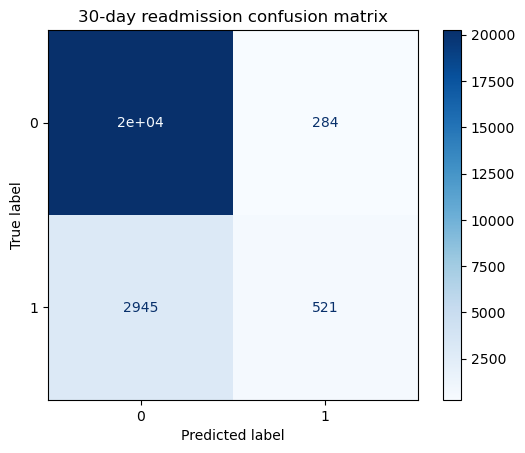

In [72]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap="Blues")
plt.title("30-day readmission confusion matrix")
plt.show()

## Check-in 8: Identify the business errors

<details>
<summary><strong>Reveal explanation</strong></summary>

- A **false positive** is a patient flagged for possible readmission who is not readmitted. The organization may spend follow-up resources unnecessarily.
- A **false negative** is a patient predicted not to be readmitted who is readmitted. The organization may miss an opportunity for additional support.

The more important error depends on the intervention cost, available staff, impact on the patient, and the organization's objectives.

</details>

## 12. Apply the fitted workflow to new records
The two examples below use the same predictor schema as the training data. We do not manually impute, scale, or encode them. The fitted pipeline applies the learned transformations consistently.

### Why predict new records at the end?
The final test demonstrates the practical value of the pipeline. The new records contain the same predictor columns used for training, including one missing BMI value.

We do not manually fill that BMI or recreate dummy variables. The pipeline applies the already learned median, scaling values, and one-hot structure.

`predict()` returns the final 0/1 class. `predict_proba()` returns a probability estimate. A probability can support ranking or resource planning, but it is not certainty and should not be treated as a clinical recommendation.

In [76]:
new_patients = pd.DataFrame({
    "age": [72, 34],
    "gender": ["Female", "Male"],
    "region": ["Edmonton", "Calgary"],
    "bmi": [33.5, np.nan],
    "systolic_bp": [152, 118],
    "cholesterol_mmol_l": [6.2, 4.1],
    "hba1c_pct": [7.4, 5.2],
    "smoker_status": ["Former", "Never"],
    "activity_level": ["Low", "High"],
    "chronic_conditions": [3, 0],
    "prior_admissions": [2, 0],
    "avg_visit_cost": [1350, 290],
    "insurance_type": ["Government", "Private"],
    "appointment_wait_days": [14, 3],
    "missed_appointments": [2, 0],
    "high_service_use": ["Yes", "No"],
    "risk_measure_count": [3, 0]
})

new_patients["predicted_readmission"] = model.predict(new_patients)
new_patients["readmission_probability"] = model.predict_proba(new_patients)[:, 1].round(3)
new_patients

,age,gender,region,bmi,systolic_bp,cholesterol_mmol_l,hba1c_pct,smoker_status,activity_level,chronic_conditions,prior_admissions,avg_visit_cost,insurance_type,appointment_wait_days,missed_appointments,high_service_use,risk_measure_count,predicted_readmission,readmission_probability
0,72,Female,Edmonton,33.5,152,6.2,7.4,Former,Low,3,2,1350,Government,14,2,Yes,3,1,0.835
1,34,Male,Calgary,NaN,118,4.1,5.2,Never,High,0,0,290,Private,3,0,No,0,0,0.018


## 13. Assignment and project transfer

### Assignment 2
The same workflow supports the `loan_status` classification task:

1. inspect dirty or missing values;
2. identify numerical and categorical columns;
3. split before fitting preprocessing;
4. place imputation, encoding, and scaling inside the pipeline;
5. fit a classifier;
6. evaluate using appropriate classification metrics;
7. reuse the fitted workflow when unseen data are released.

### Term Project
Apply the same pipeline thinking to two separate tasks:

- `Salary` is a **regression target**.
- `Salary Grade` is a **classification target**.

Because Salary Grade is created directly from Salary using the project threshold, **do not include `Salary` as a predictor in the Salary Grade classifier**. Doing so would directly reveal the target and cause leakage.

## Final student review checklist

### Data understanding and cleaning
- [ ] I can explain the business question and target.
- [ ] I can inspect the shape, types, missingness, duplicates, and target balance.
- [ ] I can distinguish identifiers, numerical fields, categorical fields, and the target.
- [ ] I can convert dirty numeric text safely.
- [ ] I can apply documented range rules without treating invalid values as real zeros.
- [ ] I can standardize category aliases and explain what happens to unmapped values.

### Leakage-safe workflow
- [ ] I can explain why the split happens before fitted preprocessing.
- [ ] I can build numerical and categorical pipelines.
- [ ] I can use `ColumnTransformer` to combine the branches.
- [ ] I can connect preprocessing and a classifier in one `Pipeline`.
- [ ] I can apply the fitted pipeline to test and future records.

### Business interpretation
- [ ] I can interpret accuracy, precision, recall, and a confusion matrix.
- [ ] I can explain false positives and false negatives in the readmission case.
- [ ] I can connect metric choice to service costs and organizational capacity.
- [ ] I can explain why an understandable engineered feature still requires evidence.
- [ ] I can identify the Salary-to-Salary-Grade leakage risk in the Term Project.

<details>
<summary><strong>Reveal the complete workflow summary</strong></summary>

1. Define the business question, target, prediction time, and intended action.
2. Load and inspect the one health dataset.
3. preserve the raw import and clean a working copy.
4. standardize missing tokens, remove duplicates, convert types, validate ranges, and normalize categories.
5. create only defensible features available at prediction time.
6. separate identifiers, predictors, and target.
7. create a protected train-test split.
8. build numerical and categorical preprocessing branches.
9. combine them with `ColumnTransformer`.
10. connect preprocessing and logistic regression in one `Pipeline`.
11. fit using training data and evaluate using untouched test data.
12. interpret errors in business language and apply the same fitted workflow to future records.

</details>

## Exit ticket
In three or four sentences, explain:

1. one dirty-data problem you found;
2. how you cleaned it;
3. one leakage risk prevented by the pipeline;
4. one business reason recall might matter for readmission planning.